# Christmas winners: eBay history → Etsy advertising candidates

This notebook answers a narrow business question: **which products performed during the last two completed Christmas seasons on eBay, and which active listings in our Etsy shop are genuinely similar?**

It is deliberately read-only with respect to both marketplaces. It does not change ads, titles, inventory, or listings. It may refresh an expired OAuth token through the project's existing auth service.

Important limitations:

- eBay gross item revenue is not profit. Product cost, shipping, refunds, fees, and labor are not available from the order response.
- eBay currently exposes a rolling two-year order window. Run this promptly or the oldest 2024 holiday orders will roll out of reach.
- An eBay winner is only a prior for Etsy. The final advertising decision still needs Etsy conversion, margin, delivery capacity, and policy eligibility.
- The optional LLM receives only product titles and categories—never buyer, address, or order data.

## 0. One-time notebook setup

Use the repository virtual environment. From the project root run:

```bash
venv/bin/pip install -r notebooks/requirements.txt
venv/bin/python -m ipykernel install --user --name ebay-shopify-sync --display-name 'eBay Shopify Sync'
```

Then select the **eBay Shopify Sync** kernel. The notebook reads the existing `.env` and Mongo-stored OAuth tokens.

In [1]:
from pathlib import Path
from datetime import date, datetime, timedelta, timezone
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

# Make imports and .env resolution work whether Jupyter starts in the repo or notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in candidates if (path / 'app').is_dir())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))

from app.config import settings
from app.database.mongo import db
from app.services.ebay_auth_service import get_valid_token as get_ebay_token
from app.services.etsy_auth_service import get_valid_token as get_etsy_token
from christmas_marketplace_analysis import (
    build_candidate_pairs,
    fetch_ebay_orders,
    fetch_etsy_listings,
    flatten_ebay_orders,
    llm_match_review,
    taxonomy_category_index,
)

pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 40)
print('Project root:', PROJECT_ROOT)

Project root: /Users/administrator/Desktop/Dev/ebay-shopify-sync


## 1. Analysis settings

The default window is November 1 through December 31 for the two most recently completed Christmas seasons. The end timestamp is exclusive.

In [2]:
TODAY = datetime.now(timezone.utc).date()
last_completed_christmas_year = TODAY.year if TODAY >= date(TODAY.year, 12, 26) else TODAY.year - 1
holiday_years = [last_completed_christmas_year - 1, last_completed_christmas_year]
HOLIDAY_WINDOWS = {
    str(year): (
        f'{year}-11-01T00:00:00.000Z',
        f'{year + 1}-01-01T00:00:00.000Z',
    )
    for year in holiday_years
}

ETSY_SHOP_ID = os.getenv('ETSY_SHOP_ID', '').strip()  # Leave blank to resolve it from Mongo.
ETSY_STATES = ('active',)  # Only active products can be advertised. Add 'draft' for research if needed.
TOP_EBAY_PRODUCTS = 50
CANDIDATES_PER_WINNER = 5
MINIMUM_LEXICAL_SCORE = 12.0
RUN_LLM_REVIEW = False  # Set True after reviewing the lexical candidate table.
RUN_LLM_CATEGORY_INFERENCE = False  # Set True only to refresh the cached controlled categories.
CATEGORY_MODEL = os.getenv('OPENAI_CATEGORY_MODEL', 'gpt-4.1-mini')
LLM_MODEL = os.getenv('OPENAI_MATCH_MODEL', 'gpt-5-mini')
MAX_LLM_PAIRS = 60
EXPORT_RESULTS = True
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'christmas-ebay-to-etsy'

oldest_supported = TODAY - timedelta(days=730)
print('Holiday windows:', HOLIDAY_WINDOWS)
if date(holiday_years[0], 11, 1) < oldest_supported:
    print('WARNING: The first holiday window begins outside eBay’s rolling two-year API history.')

Holiday windows: {'2024': ('2024-11-01T00:00:00.000Z', '2025-01-01T00:00:00.000Z'), '2025': ('2025-11-01T00:00:00.000Z', '2026-01-01T00:00:00.000Z')}


## 2. Read catalog metadata from Mongo

The Fulfillment API provides sold titles, SKUs, and item IDs but usually not useful eBay category paths. We enrich the historical line items from the repository's `product_raw` collection. Missing categories deliberately fall back to normalized title families later.

In [3]:
async def load_local_metadata():
    projection = {
        '_id': 1, 'raw.ItemID': 1, 'raw.SKU': 1, 'raw.Title': 1,
        'raw.PrimaryCategoryID': 1, 'raw.PrimaryCategoryName': 1,
        'raw.PrimaryCategoryPath': 1,
    }
    by_item_id, by_sku = {}, {}
    async for doc in db.product_raw.find({}, projection):
        raw = doc.get('raw') or {}
        sku = str(raw.get('SKU') or doc.get('_id') or '').strip()
        item_id = str(raw.get('ItemID') or '').strip()
        row = {
            'sku': sku,
            'item_id': item_id,
            'title': raw.get('Title'),
            'category_id': raw.get('PrimaryCategoryID'),
            'category': raw.get('PrimaryCategoryName'),
            'category_path': raw.get('PrimaryCategoryPath') or raw.get('PrimaryCategoryName'),
        }
        if item_id:
            by_item_id[item_id] = row
        if sku:
            by_sku[sku] = row

    shop_id = ETSY_SHOP_ID
    if not shop_id:
        linked = await db.product_normalized.find_one(
            {'channels.etsy.shop_id': {'$exists': True, '$ne': None}},
            {'channels.etsy.shop_id': 1},
        )
        shop_id = str((((linked or {}).get('channels') or {}).get('etsy') or {}).get('shop_id') or '')
    if not shop_id:
        investigation = await db.etsy_listings_investigation.find_one(
            {'shop_id': {'$exists': True, '$ne': None}}, {'shop_id': 1}
        )
        shop_id = str((investigation or {}).get('shop_id') or '')

    snapshot = await db.etsy_seller_taxonomy_snapshots.find_one(
        {'active': True}, sort=[('fetched_at', -1)]
    )
    taxonomy = taxonomy_category_index((snapshot or {}).get('nodes') or [])
    return by_item_id, by_sku, shop_id, taxonomy

catalog_by_item_id, catalog_by_sku, resolved_shop_id, etsy_taxonomy = await load_local_metadata()
if not resolved_shop_id:
    raise RuntimeError('Could not resolve Etsy shop ID. Set ETSY_SHOP_ID in .env or in the settings cell.')
print(f'Catalog rows: {len(catalog_by_item_id):,} by item ID / {len(catalog_by_sku):,} by SKU')
print('Etsy shop ID:', resolved_shop_id)
print(f'Etsy taxonomy nodes: {len(etsy_taxonomy):,}')

Catalog rows: 2,742 by item ID / 2,747 by SKU
Etsy shop ID: 64623797
Etsy taxonomy nodes: 3,065


## 3. Fetch historical eBay orders and the active Etsy catalog

All marketplace requests in this section are GET requests. No customer fields are retained in the analysis dataframe.

In [5]:
ebay_token = await get_ebay_token()
etsy_token = await get_etsy_token()
etsy_api_key = settings.ETSY_CLIENT_ID or os.getenv('ETSY_API_KEY', '')
if settings.ETSY_CLIENT_SECRET and etsy_api_key:
    etsy_api_key = f'{etsy_api_key}:{settings.ETSY_CLIENT_SECRET}'
if not etsy_api_key:
    raise RuntimeError('Etsy API key is not configured.')

orders_by_season = {}
for season, (start, end) in HOLIDAY_WINDOWS.items():
    orders_by_season[season] = await fetch_ebay_orders(
        ebay_token,
        start=start,
        end=end,
        marketplace_id=settings.EBAY_MARKETPLACE_ID,
    )
    print(f'eBay {season}: {len(orders_by_season[season]):,} orders')

etsy_rows = await fetch_etsy_listings(
    etsy_token,
    etsy_api_key,
    shop_id=resolved_shop_id,
    taxonomy_index=etsy_taxonomy,
    states=ETSY_STATES,
)
print(f'Etsy candidates: {len(etsy_rows):,} listings in states {ETSY_STATES}')

eBay 2024: 206 orders
eBay 2025: 252 orders
Etsy candidates: 1,085 listings in states ('active',)


## 4. Flatten and validate the sales data

Revenue below is gross item revenue and is useful for demand ranking—not profitability. A product with high revenue and poor margin is not an advertising winner.

In [7]:
line_items = []
for season, orders in orders_by_season.items():
    line_items.extend(
        flatten_ebay_orders(
            orders,
            season=season,
            catalog_by_item_id=catalog_by_item_id,
            catalog_by_sku=catalog_by_sku,
        )
    )

sales = pd.DataFrame(line_items)
if sales.empty:
    raise RuntimeError('No usable paid/non-canceled eBay line items were returned for the configured windows.')

display(pd.DataFrame({
    'orders': [sales['order_id'].nunique()],
    'line_items': [len(sales)],
    'units': [sales['units'].sum()],
    'gross_item_revenue': [sales['gross_item_revenue'].sum()],
    'unknown_category_pct': [(sales['ebay_category'].eq('Unknown').mean() * 100).round(1)],
}))

currency_summary = sales.groupby('currency', dropna=False).agg(
    units=('units', 'sum'),
    gross_item_revenue=('gross_item_revenue', 'sum'),
).sort_values('gross_item_revenue', ascending=False)
display(currency_summary)
if sales['currency'].nunique() > 1:
    print('WARNING: Do not add revenue across currencies without converting it first.')

,orders,line_items,units,gross_item_revenue,unknown_category_pct
0,442,442,442,69444.45,86.7


,units,gross_item_revenue
currency,,
USD,442,69444.45


## 5. Rank individual eBay products

The performance score favors unit demand (45%), gross item revenue (35%), and repeatability across both Christmas seasons (20%). It is a prioritization score, not a claim of profitability.

In [8]:
product_dimensions = ['ebay_item_id', 'sku', 'title', 'ebay_category', 'ebay_category_id', 'currency']
product_performance = sales.groupby(product_dimensions, dropna=False).agg(
    units=('units', 'sum'),
    orders=('order_id', 'nunique'),
    gross_item_revenue=('gross_item_revenue', 'sum'),
    seasons_sold=('season', 'nunique'),
    first_sale=('created_at', 'min'),
    last_sale=('created_at', 'max'),
).reset_index()

season_units = sales.pivot_table(
    index=product_dimensions, columns='season', values='units', aggfunc='sum', fill_value=0
).add_prefix('units_').reset_index()
product_performance = product_performance.merge(season_units, on=product_dimensions, how='left')
product_performance['unit_percentile'] = product_performance.groupby('currency')['units'].rank(pct=True)
product_performance['revenue_percentile'] = product_performance.groupby('currency')['gross_item_revenue'].rank(pct=True)
product_performance['repeatability'] = product_performance['seasons_sold'] / len(HOLIDAY_WINDOWS)
product_performance['performance_score'] = (
    100 * (
        0.45 * product_performance['unit_percentile']
        + 0.35 * product_performance['revenue_percentile']
        + 0.20 * product_performance['repeatability']
    )
).round(1)
product_performance = product_performance.sort_values(
    ['performance_score', 'units', 'gross_item_revenue'], ascending=False
).reset_index(drop=True)

display(product_performance.head(TOP_EBAY_PRODUCTS))

,ebay_item_id,sku,title,ebay_category,ebay_category_id,currency,units,orders,gross_item_revenue,seasons_sold,first_sale,last_sale,units_2025,unit_percentile,revenue_percentile,repeatability,performance_score
0,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,NaN,USD,1,1,1249.99,1,2024-11-19T04:52:10.000Z,2024-11-19T04:52:10.000Z,NaN,0.501131,1.000000,0.5,67.6
1,157367456719,EB-157367456719,Rare Huge Vintage Chinese Cloisonné & Brass Mantle Wind Up Clock Working. W Key.,Unknown,NaN,USD,1,1,1074.99,1,2025-11-02T17:42:25.000Z,2025-11-02T17:42:25.000Z,NaN,0.501131,0.997738,0.5,67.5
2,156705931113,EB-156705931113,RARE ANTIQUE ORIGINAL FRENCH NAPOLEON ERA IMPERIAL GUARD ARMORED BREASTPLATE,Unknown,NaN,USD,1,1,1062.00,1,2025-11-23T17:16:28.000Z,2025-11-23T17:16:28.000Z,NaN,0.501131,0.995475,0.5,67.4
3,157254758290,EB-157254758290,Rare Antique 1950's Capodimonte Italy Porcelain Mantel Mechanical Clock. Works.,Unknown,NaN,USD,1,1,749.99,1,2025-12-01T01:48:50.000Z,2025-12-01T01:48:50.000Z,NaN,0.501131,0.993213,0.5,67.3
4,157532097067,,1968 Tiffany & Co Sterling Silver Pen & Letter Opener Promo Set w Box Provenance,Collectibles:Pens & Writing Instruments:Desktop Items:Letter Openers,28020,USD,1,1,725.00,1,2025-12-27T20:58:28.000Z,2025-12-27T20:58:28.000Z,1.0,0.501131,0.990950,0.5,67.2
5,157489208821,,Rare Beautiful Giuseppe Armani Hawaian Woman ALOHA 1797C Ltd Edition. 40/5000.,Unknown,NaN,USD,1,1,700.00,1,2025-12-11T15:56:53.000Z,2025-12-11T15:56:53.000Z,NaN,0.501131,0.988688,0.5,67.2
6,157489216498,,"Vintage Giuseppe Armani Italy Figurine ""Vanities"" 1691C Ltd Ed 97/5000 W COA",Collectibles:Decorative Collectibles:Sculptures & Figurines,261628,USD,1,1,675.00,1,2025-12-24T22:00:05.000Z,2025-12-24T22:00:05.000Z,1.0,0.501131,0.986425,0.5,67.1
7,156966953193,EB-156966953193,Rare WWI German 1916 Prussia Kurassier cuirassier lobstertail pickelhaube helmet,Unknown,NaN,USD,1,1,625.00,1,2025-11-15T18:46:40.000Z,2025-11-15T18:46:40.000Z,NaN,0.501131,0.984163,0.5,67.0
8,157495419238,,1970 XL Black Forest Musical Cuckoo Clock Eagle Deeply Carved Hunter Works. Read,Unknown,NaN,USD,1,1,575.99,1,2025-11-25T17:07:19.000Z,2025-11-25T17:07:19.000Z,NaN,0.501131,0.980769,0.5,66.9
9,157559311915,,Rare Hermes Kachinas Scarf 90cm Silk Twill Hopi Design Blue Multicolor W Box.,"Clothing, Shoes & Accessories:Women:Women's Accessories:Scarves & Wraps",45238,USD,1,1,575.99,1,2025-12-27T14:37:47.000Z,2025-12-27T14:37:47.000Z,1.0,0.501131,0.980769,0.5,66.9


## 6. Legacy category/product-type performance (superseded)

This is the original title-fragment fallback. It is retained for auditability, but the controlled LLM table below supersedes it because the fallback created almost one group per product.

,group_key,currency,units,orders,gross_item_revenue,distinct_products,seasons_sold,units_per_product
0,Collectibles:Decorative Collectibles:Sculptures & Figurines,USD,9,9,1859.56,9,1,1.0
1,Pottery & Glass:Drinkware & Barware:Drinkware,USD,4,4,497.99,4,1,1.0
2,90cm blue box design herme hopi,USD,2,2,945.35,2,1,1.0
3,Collectibles:Kitchen & Home:Dinnerware & Serveware:Teapots & Tea Sets,USD,2,2,655.00,2,1,1.0
4,Collectibles:Tobacciana:Cases,USD,2,2,499.10,2,1,1.0
5,cond figurine fishnet herend mint rust,USD,2,2,437.00,2,1,1.0
6,"Jewelry & Watches:Watches, Parts & Accessories:Watches:Wristwatches",USD,2,2,298.00,2,1,1.0
7,duck figurine fishnet handpainted herend porcelain,USD,2,2,285.83,2,1,1.0
8,Collectibles:Holiday & Seasonal:Ornaments,USD,2,2,179.98,2,1,1.0
9,Jewelry & Watches:Vintage & Antique Jewelry:Bracelets & Charms,USD,2,2,130.00,2,1,1.0


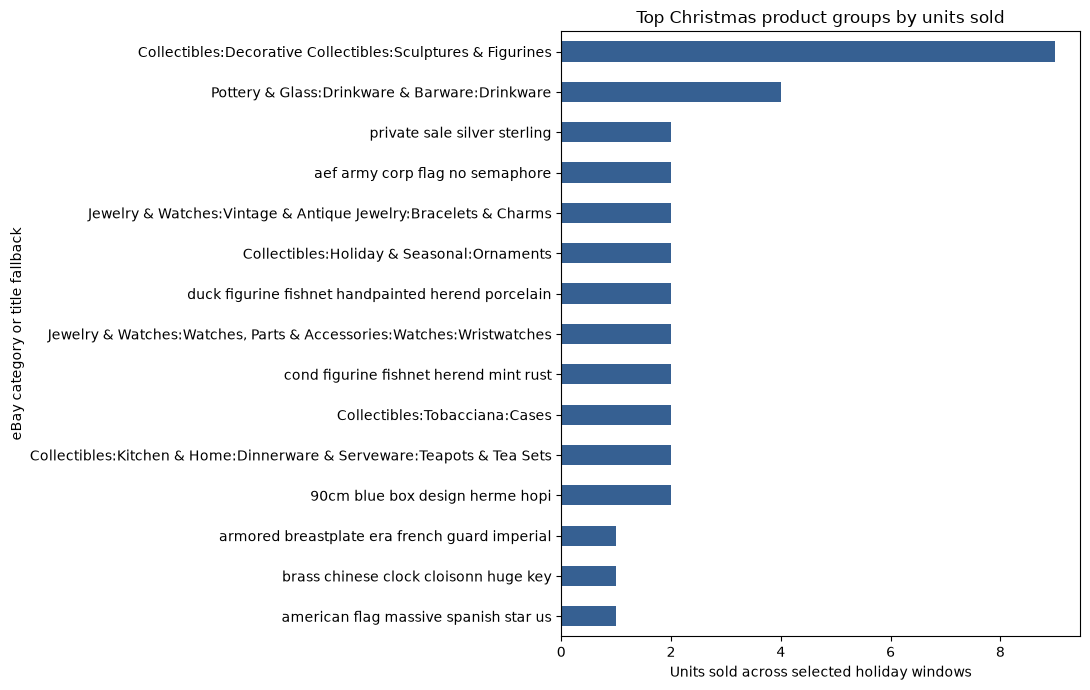

In [9]:
category_performance = sales.groupby(['group_key', 'currency'], dropna=False).agg(
    units=('units', 'sum'),
    orders=('order_id', 'nunique'),
    gross_item_revenue=('gross_item_revenue', 'sum'),
    distinct_products=('ebay_item_id', 'nunique'),
    seasons_sold=('season', 'nunique'),
).reset_index()
category_performance['units_per_product'] = (
    category_performance['units'] / category_performance['distinct_products'].clip(lower=1)
).round(2)
category_performance = category_performance.sort_values(
    ['units', 'gross_item_revenue'], ascending=False
).reset_index(drop=True)
display(category_performance.head(30))

top_chart = category_performance.head(15).sort_values('units')
ax = top_chart.plot.barh(x='group_key', y='units', figsize=(11, 7), legend=False, color='#366092')
ax.set_title('Top Christmas product groups by units sold')
ax.set_xlabel('Units sold across selected holiday windows')
ax.set_ylabel('eBay category or title fallback')
plt.tight_layout()
plt.show()

## 6b. Controlled LLM category performance (recommended)

The language model assigns every product to one fixed commercial product-type taxonomy. For the 86.7% without useful eBay category metadata, it infers from title; known eBay categories are retained and normalized. The detailed export records the source, confidence, and short reason. Only item IDs, titles, and existing category text are sent—never buyer or order data.

In [ ]:
llm_product_path = OUTPUT_DIR / 'ebay_christmas_product_performance_llm_categories.csv'
llm_category_path = OUTPUT_DIR / 'ebay_christmas_category_performance_llm.csv'

if RUN_LLM_CATEGORY_INFERENCE:
    llm_env = os.environ.copy()
    llm_env['OPENAI_CATEGORY_MODEL'] = CATEGORY_MODEL
    subprocess.run(
        [sys.executable, str(PROJECT_ROOT / 'scripts' / 'rebuild_christmas_categories_llm.py')],
        cwd=PROJECT_ROOT, env=llm_env, check=True,
    )

if not llm_category_path.exists():
    raise FileNotFoundError('No cached LLM category table. Set RUN_LLM_CATEGORY_INFERENCE=True and rerun this cell.')

llm_product_performance = pd.read_csv(llm_product_path, dtype={'ebay_item_id': 'string'})
category_performance = pd.read_csv(llm_category_path)
display(category_performance)

top_chart = category_performance.head(15).sort_values('total_units')
ax = top_chart.plot.barh(
    x='analysis_category', y='total_units', figsize=(11, 7), legend=False, color='#366092'
)
ax.set_title('Christmas sales by controlled product category')
ax.set_xlabel('Units sold across the displayed date ranges')
ax.set_ylabel('LLM-normalized product category')
plt.tight_layout()
plt.show()

## 7. Generate Etsy candidate matches

This stage uses transparent lexical similarity across eBay title/category and Etsy title/tags/taxonomy. It deliberately produces candidates—not final matches. Inspect low-scoring or broad-category results before enabling the LLM review.

In [10]:
winner_records = product_performance.head(TOP_EBAY_PRODUCTS).to_dict('records')
candidate_rows = build_candidate_pairs(
    winner_records,
    etsy_rows,
    top_n=CANDIDATES_PER_WINNER,
    minimum_score=MINIMUM_LEXICAL_SCORE,
)
candidate_matches = pd.DataFrame(candidate_rows)
if candidate_matches.empty:
    print('No Etsy candidates cleared the lexical threshold. Lower it cautiously or inspect taxonomy coverage.')
else:
    candidate_matches = candidate_matches.sort_values(
        ['performance_score', 'lexical_score'], ascending=False
    ).reset_index(drop=True)
    display(candidate_matches.head(100))

,ebay_item_id,ebay_sku,ebay_title,ebay_category,performance_score,units,gross_item_revenue,etsy_listing_id,etsy_title,etsy_category,etsy_state,etsy_price,etsy_url,lexical_score,token_jaccard,title_similarity,category_similarity
0,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4569912498,Original 1918 WWI American Library Association &#39;HEY FELLOWS&#39; Framed Propaganda Poster Co...,Art & Collectibles > Collectibles > Memorabilia > Militaria,active,384.21,https://www.etsy.com/listing/4569912498/original-1918-wwi-american-library,23.81,0.1304,0.3743,0.0345
1,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4462541167,Antique 19th C Translucent Civil War Era American Natural Powder Horn 9&quot; Long.,Clothing > Girls' Clothing > Dresses,active,145.94,https://www.etsy.com/listing/4462541167/antique-19th-c-translucent-civil-war-era,20.63,0.1053,0.4079,0.1053
2,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4592303671,Rare Civil War Dug Bullet Relic Collection 1862-64 Virginia Battlefields US CSA Militaria,Art & Collectibles > Collectibles > Memorabilia > Militaria,active,435.99,https://www.etsy.com/listing/4592303671/rare-civil-war-dug-bullet-relic,20.36,0.1111,0.2424,0.0345
3,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4574306723,Framed Early 1800s Salisbury MA Tax Receipts (1814-1840),Art & Collectibles > Collectibles > Memorabilia,active,183.53,https://www.etsy.com/listing/4574306723/framed-early-1800s-salisbury-ma-tax,17.55,0.0800,0.3385,0.0417
4,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4458603559,Lot Of 28 Authentic Antique Original Native American Arrowheads In Display Tray.,Toys & Games > Sports & Outdoor Recreation > Hunting & Archery > Hunting,active,466.19,https://www.etsy.com/listing/4458603559/lot-of-28-authentic-antique-original,17.37,0.0500,0.5290,0.1194
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,157517798005,,19th C French Art Nouveau Figural Bronze Crystal Inkwell Desk Set Sterling Pen,Unknown,66.0,1,450.00,4574306399,Antique French Bronze Lourdes Mary Statue Inkwell - Religious Collectible Christian Art,"Craft Supplies & Tools > Paints, Inks & Dyes > Inks > Inkwells",active,97.43,https://www.etsy.com/listing/4574306399/antique-french-bronze-lourdes-mary,26.23,0.1333,0.4785,0.1724
96,157517798005,,19th C French Art Nouveau Figural Bronze Crystal Inkwell Desk Set Sterling Pen,Unknown,66.0,1,450.00,4569916056,Vintage Lalique Crystal Mermaid Figurine Signed French Art Nouveau Glass Collectible 1980s,Art & Collectibles > Collectibles > Figurines & Knick Knacks,active,170.01,https://www.etsy.com/listing/4569916056/vintage-lalique-crystal-mermaid-figurine,24.16,0.1538,0.3333,0.1695
97,157517798005,,19th C French Art Nouveau Figural Bronze Crystal Inkwell Desk Set Sterling Pen,Unknown,66.0,1,450.00,4569900069,Set of 2 French Bronze Putti Cherubs Holding Wine Cups – 19th Century Figurative Art,Art & Collectibles > Sculpture > Figurines,active,846.21,https://www.etsy.com/listing/4569900069/set-of-2-french-bronze-putti-cherubs,23.49,0.1481,0.3500,0.0930
98,157517798005,,19th C French Art Nouveau Figural Bronze Crystal Inkwell Desk Set Sterling Pen,Unknown,66.0,1,450.00,4574330252,Antique Art Nouveau Baltic Amber Pendant Necklace 925 Sterling Silver Vintage Jewelry,Jewelry > Necklaces > Pendant Necklaces,active,285.93,https://www.etsy.com/listing/4574330252/antique-art-nouveau-baltic-amber-pendant,23.22,0.1364,0.4294,0.1905


## 8. Optional conservative LLM review

Set `RUN_LLM_REVIEW = True` in the settings cell only after inspecting the candidate table. The LLM is asked whether two listings are the same practical product type. It may also suggest a restrained holiday title when Christmas or gifting is genuinely relevant. Suggestions are never published.

In [11]:
reviewed_matches = candidate_matches.copy()
if RUN_LLM_REVIEW and not candidate_matches.empty:
    if not settings.OPENAI_API_KEY:
        raise RuntimeError('OPENAI_API_KEY is required when RUN_LLM_REVIEW=True.')
    from openai import OpenAI
    llm_client = OpenAI(api_key=settings.OPENAI_API_KEY)
    reviewed_rows = llm_match_review(
        llm_client,
        candidate_matches.head(MAX_LLM_PAIRS).to_dict('records'),
        model=LLM_MODEL,
    )
    reviewed_matches = pd.DataFrame(reviewed_rows)
    display(reviewed_matches.head(MAX_LLM_PAIRS))
else:
    print('LLM review skipped. Candidate ranking remains lexical and requires human review.')

LLM review skipped. Candidate ranking remains lexical and requires human review.


## 9. Produce a human-review shortlist

Without LLM review, the table keeps the highest lexical candidate per eBay winner. With LLM review, it keeps only conservative positive matches with confidence of at least 0.65. This is still not an automatic advertising list: verify contribution margin, Etsy conversion, stock, processing time, and policy eligibility.

In [13]:
if reviewed_matches.empty:
    shortlist = reviewed_matches.copy()
elif RUN_LLM_REVIEW:
    shortlist = reviewed_matches.loc[
        reviewed_matches['same_product_type'].fillna(False)
        & reviewed_matches['confidence'].ge(0.65)
    ].copy()
    shortlist = shortlist.sort_values(
        ['performance_score', 'confidence', 'lexical_score'], ascending=False
    ).drop_duplicates(['etsy_listing_id'], keep='first')
else:
    shortlist = reviewed_matches.sort_values(
        ['performance_score', 'lexical_score'], ascending=False
    ).groupby(['ebay_item_id', 'ebay_sku'], dropna=False, as_index=False).head(1)

display(shortlist.head(100))
print(f'Shortlist rows requiring human review: {len(shortlist):,}')

,ebay_item_id,ebay_sku,ebay_title,ebay_category,performance_score,units,gross_item_revenue,etsy_listing_id,etsy_title,etsy_category,etsy_state,etsy_price,etsy_url,lexical_score,token_jaccard,title_similarity,category_similarity
0,156215833799,,Massive Antique Original Spanish American War 1890's 45 Star US Flag 88” X 56”,Unknown,67.6,1,1249.99,4569912498,Original 1918 WWI American Library Association &#39;HEY FELLOWS&#39; Framed Propaganda Poster Co...,Art & Collectibles > Collectibles > Memorabilia > Militaria,active,384.21,https://www.etsy.com/listing/4569912498/original-1918-wwi-american-library,23.81,0.1304,0.3743,0.0345
5,157367456719,EB-157367456719,Rare Huge Vintage Chinese Cloisonné & Brass Mantle Wind Up Clock Working. W Key.,Unknown,67.5,1,1074.99,4458543712,Vintage Exquisite Renaissance-Style Chinese Enamel & Cloisonne Clock. Working.,Home & Living > Home Decor > Clocks,active,449.39,https://www.etsy.com/listing/4458543712/vintage-exquisite-renaissance-style,25.85,0.1579,0.5235,0.1111
10,156705931113,EB-156705931113,RARE ANTIQUE ORIGINAL FRENCH NAPOLEON ERA IMPERIAL GUARD ARMORED BREASTPLATE,Unknown,67.4,1,1062.00,4458600195,Original Rare Soviet 3rd Armored Division Spearhead Watch. Cold War Era. Works,Accessories > Pins & Clips > Pins & Pinback Buttons,active,212.09,https://www.etsy.com/listing/4458600195/original-rare-soviet-3rd-armored,19.96,0.0952,0.4079,0.0800
15,157254758290,EB-157254758290,Rare Antique 1950's Capodimonte Italy Porcelain Mantel Mechanical Clock. Works.,Unknown,67.3,1,749.99,4458523971,Vintage Set Of 2 Capodimonte Italy Porcelain Cherrubs Handpainted Lidded Urns.,Home & Living > Home Decor > Home Accents > Vases,active,459.89,https://www.etsy.com/listing/4458523971/vintage-set-of-2-capodimonte-italy,29.91,0.1765,0.5584,0.0833
20,157489208821,,Rare Beautiful Giuseppe Armani Hawaian Woman ALOHA 1797C Ltd Edition. 40/5000.,Unknown,67.2,1,700.00,4458529219,Rare Giuseppe Armani NIGHT STARS Figurine 1377c Limited Edition #844/ 5000 W COA,Art & Collectibles > Collectibles > Figurines & Knick Knacks,active,1423.79,https://www.etsy.com/listing/4458529219/rare-giuseppe-armani-night-stars,30.39,0.1579,0.6364,0.1695
21,157532097067,,1968 Tiffany & Co Sterling Silver Pen & Letter Opener Promo Set w Box Provenance,Collectibles:Pens & Writing Instruments:Desktop Items:Letter Openers,67.2,1,725.00,4569917544,Rare Antique Tiffany & Co Sterling Silver 925 Hinged Flip Matchbook Case - Vintage Art Nouveau C...,Bags & Purses > Accessory Cases > Cigarette Cases,active,363.21,https://www.etsy.com/listing/4569917544/rare-antique-tiffany-co-sterling-silver,24.77,0.1538,0.4045,0.2752
30,157489216498,,"Vintage Giuseppe Armani Italy Figurine ""Vanities"" 1691C Ltd Ed 97/5000 W COA",Collectibles:Decorative Collectibles:Sculptures & Figurines,67.1,1,675.00,4569919214,Giuseppe Armani Limited Edition Porcelain Lady with Parrot Figurine 616/C Hand Signed COA Italy,Art & Collectibles > Collectibles > Figurines & Knick Knacks,active,672.33,https://www.etsy.com/listing/4569919214/giuseppe-armani-limited-edition,47.32,0.3200,0.4852,0.5505
35,156966953193,EB-156966953193,Rare WWI German 1916 Prussia Kurassier cuirassier lobstertail pickelhaube helmet,Unknown,67.0,1,625.00,4600663997,Rare Antique WW1 German Binoculars - Original 1910s Militaria Collectible for WWI Reenactment & ...,Art & Collectibles > Collectibles > Memorabilia > Militaria,active,115.49,https://www.etsy.com/listing/4600663997/rare-antique-ww1-german-binoculars,17.22,0.0833,0.3575,0.0345
40,157495419238,,1970 XL Black Forest Musical Cuckoo Clock Eagle Deeply Carved Hunter Works. Read,Unknown,66.9,1,575.99,4606142586,Schneider Black Forest Cuckoo Clock Regula 25-C 1 Day Mechanical Wood Brass Germany 1970s,Home & Living > Home Decor > Clocks,active,300.29,https://www.etsy.com/listing/4606142586/schneider-black-forest-cuckoo-clock,29.12,0.1667,0.5119,0.1111
42,157559311915,,Rare Hermes Kachinas Scarf 90cm Silk Twill Hopi Design Blue Multicolor W Box.,"Clothing, Shoes &

Shortlist rows requiring human review: 50


## 10. Export the evidence

Exports contain product/order identifiers but no buyer PII. They are evidence files for manual review, not instructions to change Etsy.

In [14]:
if EXPORT_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    product_performance.to_csv(OUTPUT_DIR / 'ebay_christmas_product_performance.csv', index=False)
    category_performance.to_csv(OUTPUT_DIR / 'ebay_christmas_category_performance.csv', index=False)
    candidate_matches.to_csv(OUTPUT_DIR / 'etsy_candidate_matches.csv', index=False)
    shortlist.to_csv(OUTPUT_DIR / 'etsy_human_review_shortlist.csv', index=False)
    print('Wrote:', OUTPUT_DIR)

Wrote: /Users/administrator/Desktop/Dev/ebay-shopify-sync/outputs/christmas-ebay-to-etsy


## Decision rules

Do **not** advertise a candidate merely because it appears in the shortlist. A defensible Etsy advertising candidate should satisfy all of these:

1. Strong or repeatable Christmas demand on eBay.
2. A genuine product-type match—not merely the same broad category.
3. Positive contribution margin after product cost, shipping subsidy, packaging, Etsy/payment fees, variable labor, and expected refunds.
4. Enough inventory and processing capacity to arrive before Christmas.
5. Etsy policy eligibility.
6. A credible Etsy listing: strong first image, clear price, adequate description, and readable title.

The blunt interpretation: eBay history can tell us where to look. It cannot prove that an Etsy ad will be profitable.